## 1. Import libraries and configure the inference environment

In [1]:
from    typing  import  Sequence
from    itertools   import  product

from    tqdm.notebook   import  tqdm
from    time            import  perf_counter

import  torch
from    torch.utils.data                import  DataLoader

from    deep_numerical.utils            import  GaussianNormalizer, relative_error, sec_to_hms
from    deep_numerical.neural.utils     import  count_parameters
from    deep_numerical.neural.operator  import  ModifiedFNO
import  matplotlib.pyplot               as  plt

from    loader      import  NormKeys, HistKeys
from    loader      import  path_base
from    loader      import  load_model_args, load_model_data
from    dataset     import  nonparametric_dataset, parametric_dataset
from    plot        import  *


DEVICE: torch.device = torch.device("cuda:1")

list_max_freq   = [6, 8, 10]
list_seed       = [0, 1, 2]
max_freq        = list_max_freq[1]
seed            = list_seed[0]

_ = torch.empty(1, device=DEVICE)
torch.cuda.reset_peak_memory_stats(DEVICE)
torch.cuda.synchronize(DEVICE)

## 2. Instantiate the trained operators and normalizers

### 2-1. Load data (trained parameters, normalizers, and training histories)

In [2]:
model_data_fno  = load_model_data("FNO2D-param", max_freq, seed)

### 2-2. Load training history

In [3]:
hist:   dict[HistKeys, float|list[float]] = model_data_fno["train_history"]
label = "FNO"
print("Successfully loaded training histories.")

Successfully loaded training histories.


In [4]:
print(f"Training time for {label}\n>>> {sec_to_hms(int(hist['train_time']))}")

Training time for FNO
>>> 11:00:13


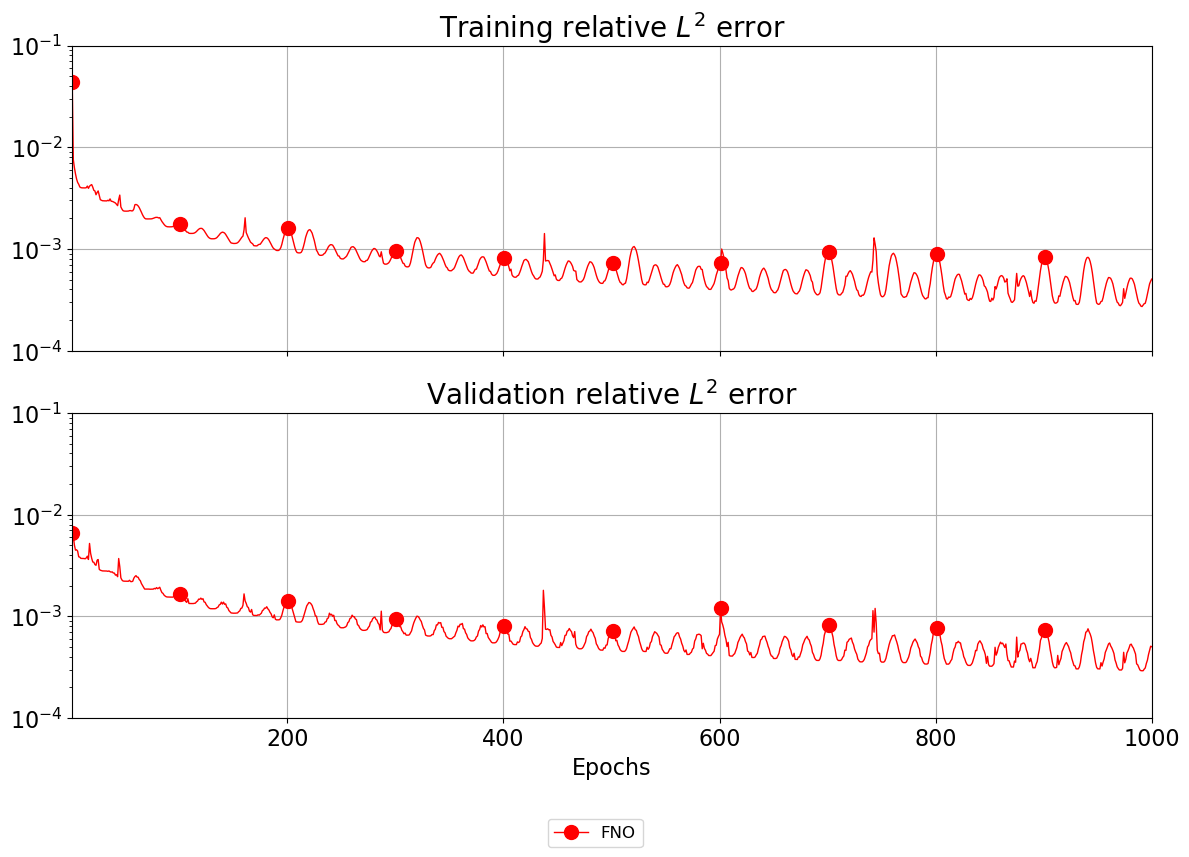

In [5]:
fig: plt.Figure
axes: Sequence[plt.Axes]
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
assert len(hist['train_rel_error'])==len(hist['train_rel_error_cons'])
assert len(hist['train_rel_error_cons'])==len(hist['val_rel_error'])
assert len(hist['val_rel_error'])==len(hist['val_rel_error_cons'])
num_epochs = len(hist['train_rel_error'])
_list_epochs = list(range(1, 1+num_epochs))
axes[0].set_title("Training relative $L^2$ error", fontsize=SIZE_TITLE)
axes[0].plot(
    _list_epochs, hist['train_rel_error'],
    linewidth=LINEWIDTH_1, color='r',
    marker='o', markevery=100, markersize=MARKERSIZE,
    label=label,
)
axes[1].set_title("Validation relative $L^2$ error", fontsize=SIZE_TITLE)
axes[1].plot(
    _list_epochs, hist['val_rel_error'],
    linewidth=LINEWIDTH_1, color='r',
    marker='o', markevery=100, markersize=MARKERSIZE,
)

for ax in axes:
    ax.set_xlim(min(_list_epochs), max(_list_epochs))
    ax.set_ylim(1e-4, 1e-1)
    ax.set_yscale('log')
    ax.tick_params(axis='both', which='major', labelsize=SIZE_TICK)
    ax.grid(True)
axes[-1].set_xlabel('Epochs', fontsize=SIZE_LABEL)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), fontsize=SIZE_LEGEND, ncols=4)
fig.tight_layout()
fig.savefig("train_validation_loss.pdf", bbox_inches='tight')

### 2-3. Load trained operators

In [6]:
model_fno   = ModifiedFNO(**load_model_args("FNO2D-param", max_freq))
model_fno.load_state_dict(  model_data_fno["state_dict"])
model_fno.to(DEVICE)
model_fno.eval()
print(f"Successfully loaded models.")

Successfully loaded models.


In [7]:
num_params = count_parameters(model_fno)
print(f"Number of parameters in {label}2D-param\n>>> {num_params}")

Number of parameters in FNO2D-param
>>> 1300001


### 2-4. Load normalizers

In [8]:
norm_fno:   dict[NormKeys, GaussianNormalizer] = model_data_fno["normalizer"]
for v in norm_fno.values():   v.to(DEVICE)
print(f"Successfully loaded normalizers.")

Successfully loaded normalizers.


## 3. Conduct inference

### 3-1. Construct dataloader

In [9]:
path_data = path_base / "datasets" / "Boltzmann_2D__coeff1.59e-01__res_t051_v128"
assert path_data.exists(), f"The data path {path_data} does not exist."
list_alpha = [0.50]
part_start, part_end = 1, 1

data, params = [], []
generation_time = 0.0
files = sorted(path_data.glob("alpha*.pth"))
alpha_and_part = list(product(list_alpha, range(part_start, part_end+1)))
for alpha, part in tqdm(alpha_and_part):
    file = path_data / f"alpha{alpha:.2f}__part{part:03d}.pth"
    f = torch.load(file, weights_only=False)
    data.append(f['data'][[0]])         # (num_instances, res_t, 1, 1, res, res, 1)
    params.append(f['vhs_alpha']*torch.ones(1, 1))     # float
    generation_time += f['elapsed_time']
data    = torch.cat(data, dim=0).to(DEVICE)               # (num_total_instances, res_t, 1, 1, res, res, 1)
params  = torch.cat(params, dim=0).to(DEVICE)           # (num_total_instances, 1)
num_inst, res_t, res_v = data.size(0), data.size(1), data.size(-2)
data    = data.view(num_inst, res_t, res_v, res_v, 1)
data    = data.type(torch.float)
params  = params.type(torch.float)

print(f"Successfully loaded dataset with {num_inst} instances.")
print(f"Time for generating dataset\n>>> {sec_to_hms(int(generation_time))}")

  0%|          | 0/1 [00:00<?, ?it/s]

Successfully loaded dataset with 1 instances.
Time for generating dataset
>>> 0:00:52


In [10]:
BATCH_SIZE = 2**6

dataloader_fno  = DataLoader(nonparametric_dataset(data, params, norm_fno), batch_size=BATCH_SIZE, shuffle=False)
print(f"Successfully prepared dataloaders.")

Successfully prepared dataloaders.


### 3-2. Compute the trajectories on the test set

FNO

In [11]:
pred_fno = []
inference_time_fno = perf_counter()

with torch.inference_mode():
    model_preds = []
    traj:   torch.Tensor
    alphas: torch.Tensor
    for traj, alphas in tqdm(dataloader_fno, desc="FNO Inference"):
        traj    = traj.to(DEVICE)
        alphas  = alphas.to(DEVICE)
        pred    = traj[:, 0]    # The initial condition of shape `(batch_size, res, res, 1)`
        # Save the initial condition
        batch_pred = [norm_fno['data'].decode(pred).cpu()]
        # Compute the trajectory
        for t in range(1, res_t):
            pred = model_fno.forward(pred, alphas)
            batch_pred.append(norm_fno['data'].decode(pred).cpu())
        batch_pred = torch.stack(batch_pred, dim=1)   # (batch_size, res_t, res, res, 1)
        model_preds.append(batch_pred)
    pred_fno = torch.cat(model_preds, dim=0)   # (num_inst, res_t, res, res, 1)

inference_time_fno = perf_counter() - inference_time_fno

FNO Inference:   0%|          | 0/1 [00:00<?, ?it/s]

In [12]:
torch.cuda.synchronize(DEVICE)
peak_memory_fno = torch.cuda.max_memory_allocated(DEVICE) / (1024**2)   # MB1
print(f"FNO Inference time: {inference_time_fno:.2f} seconds.")
print(f"FNO Peak memory usage: {peak_memory_fno:.2f} MB.")

FNO Inference time: 0.20 seconds.
FNO Peak memory usage: 42.12 MB.


End of file